# 04 · Customer Segmentation with K-Means

We cluster customers on their numeric behaviour (age, spend, clicks, impressions, conversions) using **K-Means**, choose the number of clusters with the **elbow method**, and give each segment a business-friendly name. The labelled data is saved to `data/processed/segmented_customers.parquet`.

## 1. Load the clean data

In [1]:
import pandas as pd

CLEAN_CSV = "../data/processed/clean_customers.csv"
SEGMENTED_PARQUET = "../data/processed/segmented_customers.parquet"

DATA = pd.read_csv(CLEAN_CSV)
print(DATA.shape)
DATA.dtypes

(499, 10)


customer_id       object
age              float64
gender            object
country           object
channel           object
monthly_spend    float64
clicks           float64
impressions        int64
conversions        int64
signup_date       object
dtype: object

## 2. Select features

In [2]:
FEATURES = ['age', 'monthly_spend', 'clicks', 'impressions', 'conversions']
X = DATA[FEATURES]
X.shape

(499, 5)

## 3. Scale the features

In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled

array([[-1.54556377,  0.62523449,  0.16118844,  1.37197531,  0.59124145],
       [ 1.00476818,  1.5133636 , -0.77539512, -1.5170648 , -1.44860286],
       [ 0.52658094, -0.19053564, -0.88332854, -0.32947943,  0.79522588],
       ...,
       [-0.50949141,  0.01810165,  1.77670802,  1.40823582, -0.56467033],
       [ 1.56265329,  0.01810165, -0.70576065, -1.62241338, -0.29269109],
       [-0.27039779,  0.01810165, -0.70576065,  1.55442218,  0.52324663]],
      shape=(499, 5))

## 4. Choose K with the elbow method

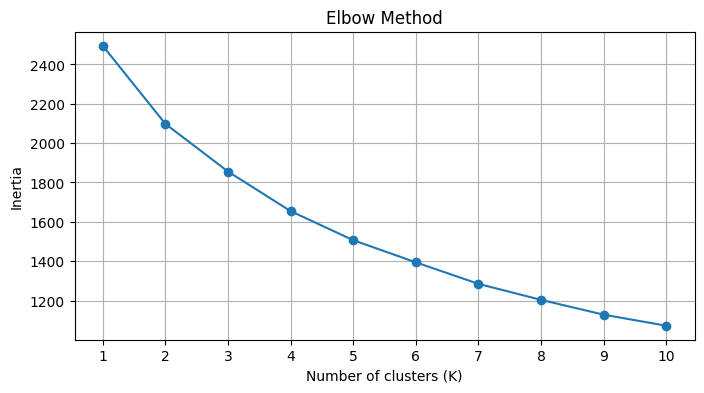

In [4]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(K_range, inertias, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.xticks(K_range)
plt.grid(True)
plt.show()

## 5. Fit the final model (K = 4)

In [5]:
km_final = KMeans(n_clusters=4, random_state=42, n_init=10)
km_final.fit(X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [6]:
DATA['segment'] = km_final.labels_
DATA['segment'].value_counts()

segment
2    132
1    129
3    121
0    117
Name: count, dtype: int64

## 6. Profile each segment

In [7]:
segment_profile = DATA.groupby('segment')[FEATURES].mean().round(1)
segment_profile

,age,monthly_spend,clicks,impressions,conversions
segment,,,,,
0,39.7,2289.2,243.3,28885.6,11.0
1,40.2,3349.5,399.4,12240.5,33.8
2,41.7,1909.4,767.8,20910.6,18.4
3,43.9,2651.3,492.0,38415.7,37.6


In [8]:
DATA.groupby('segment')['age'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
segment,,,,,,,,
0,117.0,39.7,11.5,18.0,32.0,41.0,46.0,64.0
1,129.0,40.2,12.4,18.0,31.0,41.0,50.0,64.0
2,132.0,41.7,13.0,18.0,30.8,41.0,53.0,64.0
3,121.0,43.9,13.0,18.0,35.0,44.0,55.0,64.0


## 7. Name the segments

| Segment | Name | Profile |
|---|---|---|
| 0 | **Ghosts** | Fewest clicks and conversions — they barely engage |
| 1 | **Whales** | Highest spend; convert a lot from few impressions |
| 2 | **Browsers** | Most clicks, but low conversions and the lowest spend |
| 3 | **Core Buyers** | Most impressions and the highest conversions, solid spend |

In [9]:
segment_names = {
    0: 'Ghosts',
    1: 'Whales',
    2: 'Browsers',
    3: 'Core Buyers'
}

DATA['segment_name'] = DATA['segment'].map(segment_names)
DATA['segment_name'].value_counts()

segment_name
Browsers       132
Whales         129
Core Buyers    121
Ghosts         117
Name: count, dtype: int64

## 8. Visualize the segments

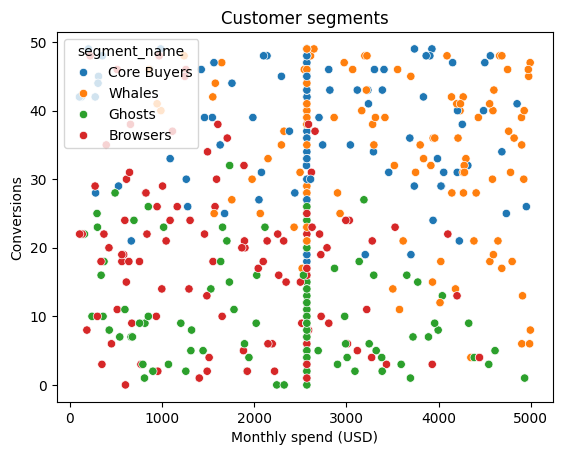

In [10]:
import seaborn as sns

sns.scatterplot(x=DATA['monthly_spend'], y=DATA['conversions'], hue=DATA['segment_name'])
plt.xlabel('Monthly spend (USD)')
plt.ylabel('Conversions')
plt.title('Customer segments')
plt.show()

## 9. Save the segmented data

In [11]:
DATA.to_parquet(SEGMENTED_PARQUET, index=False)
print(f"✓ Saved to '{SEGMENTED_PARQUET}'")

✓ Saved to '../data/processed/segmented_customers.parquet'
